<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQk4anYFFsY3OTqb6RP4oTBhqPM0P1u80tSRA&usqp=CAU" width=75 height=50>

*Algirdas Laukaitis* — originalus Colab CNN užrašų knygelės autorius.

Ši versija: **1.4 užduotis** (Gilusis mokymas, VILNIUS TECH). Originalas pakartotas ląstelė po ląstelės, bet CIFAR-10 pakeistas **tf_flowers** duomenų rinkiniu.

<br><br>

---



# PART 1

Trumpai: 1 dalyje paruošiame vaizdus, sudarome konvoliucinį tinklą (CNN), jį apmokome ir įvertiname tikslumą.

<font color='SeaGreen'>Download and prepare the tf_flowers dataset</font>        <img src="https://storage.googleapis.com/tfds-data/visualization/fig/tf_flowers-3.0.1.png" width=100 height=100>

**Kodėl ne CIFAR-10?** Dėstytojo Colab naudoja CIFAR-10 (32×32 RGB, 10 klasių: lėktuvas, automobilis, katė ir t. t.). Užduotis reikalauja **kitų** viešai atsisiunčiamų vaizdų. Pasirinktas `tf_flowers`: 5 gėlių rūšys, RGB nuotraukos, ~3670 vaizdų, archyvas iš Google Storage be Kaggle prisijungimo. Vaizdai sumažinami iki 32×32, kad CNN architektūra liktų tokia pati kaip originalo, o 2 dalies RGB filtrų vizualizacija veiktų be pakeitimų.

In [1]:
#@title Kodas, kuris įkelia tf_flowers rinkinį — RGB gėlių nuotraukas (5 klasės).

import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

# Originaliame Colab: class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
# Originaliame Colab Keras CIFAR-10 atsisiuntimas buvo praleistas (lėtas), o duomenys krauti iš Hugging Face.
# Čia Keras load_data() netinka — tf_flowers nėra Keras bundled rinkinys.
class_names = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


I0000 00:00:1792562914.582193    2925 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792562915.556141    2925 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


**Kaip veikia duomenų įkėlimas.** Originaliame dokumente 6 ląstelė darė `load_dataset("uoft-cs/cifar10")` ir sudėjo `img` / `label` į `numpy` masyvus. Čia tas pats galutinis formatas (`train_images`, `train_labels`, `test_images`, `test_labels`), tik šaltinis kitas: viešas TensorFlow `flower_photos.tgz` archyvas. Klasės imamos iš aplankų vardų, vaizdai keičiami į 32×32, tada 80/20 treniravimo/testo dalijimas (fiksuotas `seed=42`).

In [2]:
import os
import pathlib
from PIL import Image

dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = tf.keras.utils.get_file(
    fname="flower_photos.tgz",
    origin=dataset_url,
    extract=True,
)
archive_path = pathlib.Path(archive)
data_dir = None
for dirpath, dirnames, _ in os.walk(archive_path.parent):
    if "daisy" in dirnames and "tulips" in dirnames:
        data_dir = pathlib.Path(dirpath)
        break
if data_dir is None:
    raise FileNotFoundError(f"tf_flowers not found under {archive_path.parent}")
print("data_dir:", data_dir)

img_size = 32
images = []
labels = []
for label, class_name in enumerate(class_names):
    class_dir = data_dir / class_name
    for path in sorted(class_dir.glob("*.jpg")):
        img = Image.open(path).convert("RGB").resize((img_size, img_size), Image.Resampling.BILINEAR)
        images.append(np.array(img, dtype=np.uint8))
        labels.append(label)

images = np.stack(images)
labels = np.array(labels, dtype=np.int64).reshape(-1, 1)

rng = np.random.default_rng(42)
idx = rng.permutation(len(images))
split = int(0.8 * len(images))
train_idx, test_idx = idx[:split], idx[split:]
train_images, test_images = images[train_idx], images[test_idx]
train_labels, test_labels = labels[train_idx], labels[test_idx]

print("train:", train_images.shape, train_labels.shape)
print("test:", test_images.shape, test_labels.shape)
print("counts:", {n: int((labels[:, 0] == i).sum()) for i, n in enumerate(class_names)})


data_dir: /home/ubuntu/.keras/datasets/flower_photos_extracted/flower_photos


train: (2936, 32, 32, 3) (2936, 1)
test: (734, 32, 32, 3) (734, 1)
counts: {'daisy': 633, 'dandelion': 898, 'roses': 641, 'sunflowers': 699, 'tulips': 799}


In [3]:
#@title Normalizing the pixel values is crucial, ensuring our data is ready for the challenges ahead

# Pixeliai 0..255 pakeičiami į 0..1 — taip Adam optimizatorius ir ReLU sluoksniai stabiliau mokosi.
train_images, test_images = train_images / 255.0, test_images / 255.0


<br><br>

---
###<font color='SeaGreen'>Let's plot the first 100 images </font>

Pirmi 100 treniravimo vaizdų — greita patikra, kad etiketės ir RGB kanalai sutampa su tuo, ką matome.

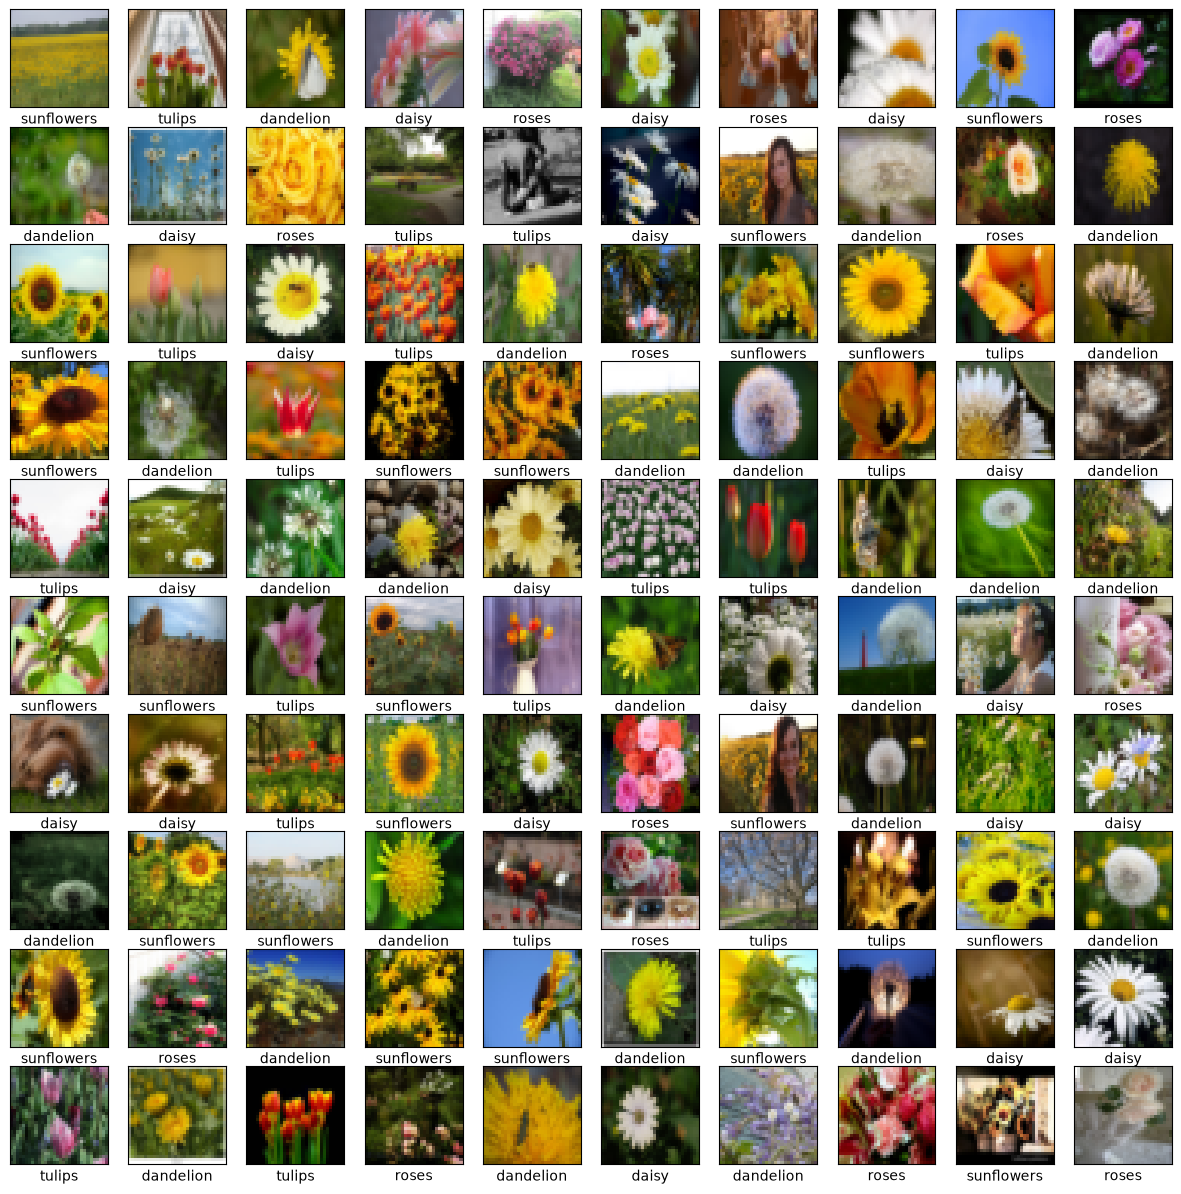

In [4]:
#@title Peržiūrime šimtą tf_flowers vaizdų, kad įsitikintume, jog duomenys sveiki.
plt.figure(figsize=(15,15))
for i in range(100):
    plt.subplot(10,10,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()




<br><br><br><br>


# <font color='SeaGreen'>Convolutional Neural Network</font>        <img src="https://upload.wikimedia.org/wikipedia/commons/6/63/Typical_cnn.png" width=500 height=150>

**Kaip veikia CNN.** Konvoliucinis sluoksnis slankioja mažu filtru (čia 3×3) per vaizdą ir skaičiuoja skaliarinę sandaugą — taip randami lokalūs šablonai (kraštinės, spalvos, tekstūros). `MaxPooling2D(2,2)` sumažina erdvinį dydį perpus, palikdamas stipriausią signalą. Po kelių konvoliucijų `Flatten` paverčia žemėlapį vektoriumi, o `Dense` sluoksniai priima klasės sprendimą. Originalo išėjimas turėjo 10 neuronų (CIFAR-10); čia **5**, nes tf_flowers turi 5 klases. Visa kita architektūra palikta identiška.

<br><br>

---
###<font color='SeaGreen'>Step 2. Model </font>


In [5]:
model = models.Sequential()

model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(5))
'''
model.add(layers.Flatten(input_shape=(32, 32, 3)))
model.add(layers.Dense(5))
'''


/home/ubuntu/.local/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1792562923.170636    2925 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


'\nmodel.add(layers.Flatten(input_shape=(32, 32, 3)))\nmodel.add(layers.Dense(5))\n'

In [6]:

model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),  metrics=['accuracy'])

model.summary() # Number of parameters per filter: (filter size * input channels) + 1 (bias)  ; Total parameters: number of filters * parameters per filter


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,245 (477.52 KB)

 Trainable params: 122,245 (477.52 KB)

 Non-trainable params: 0 (0.00 B)

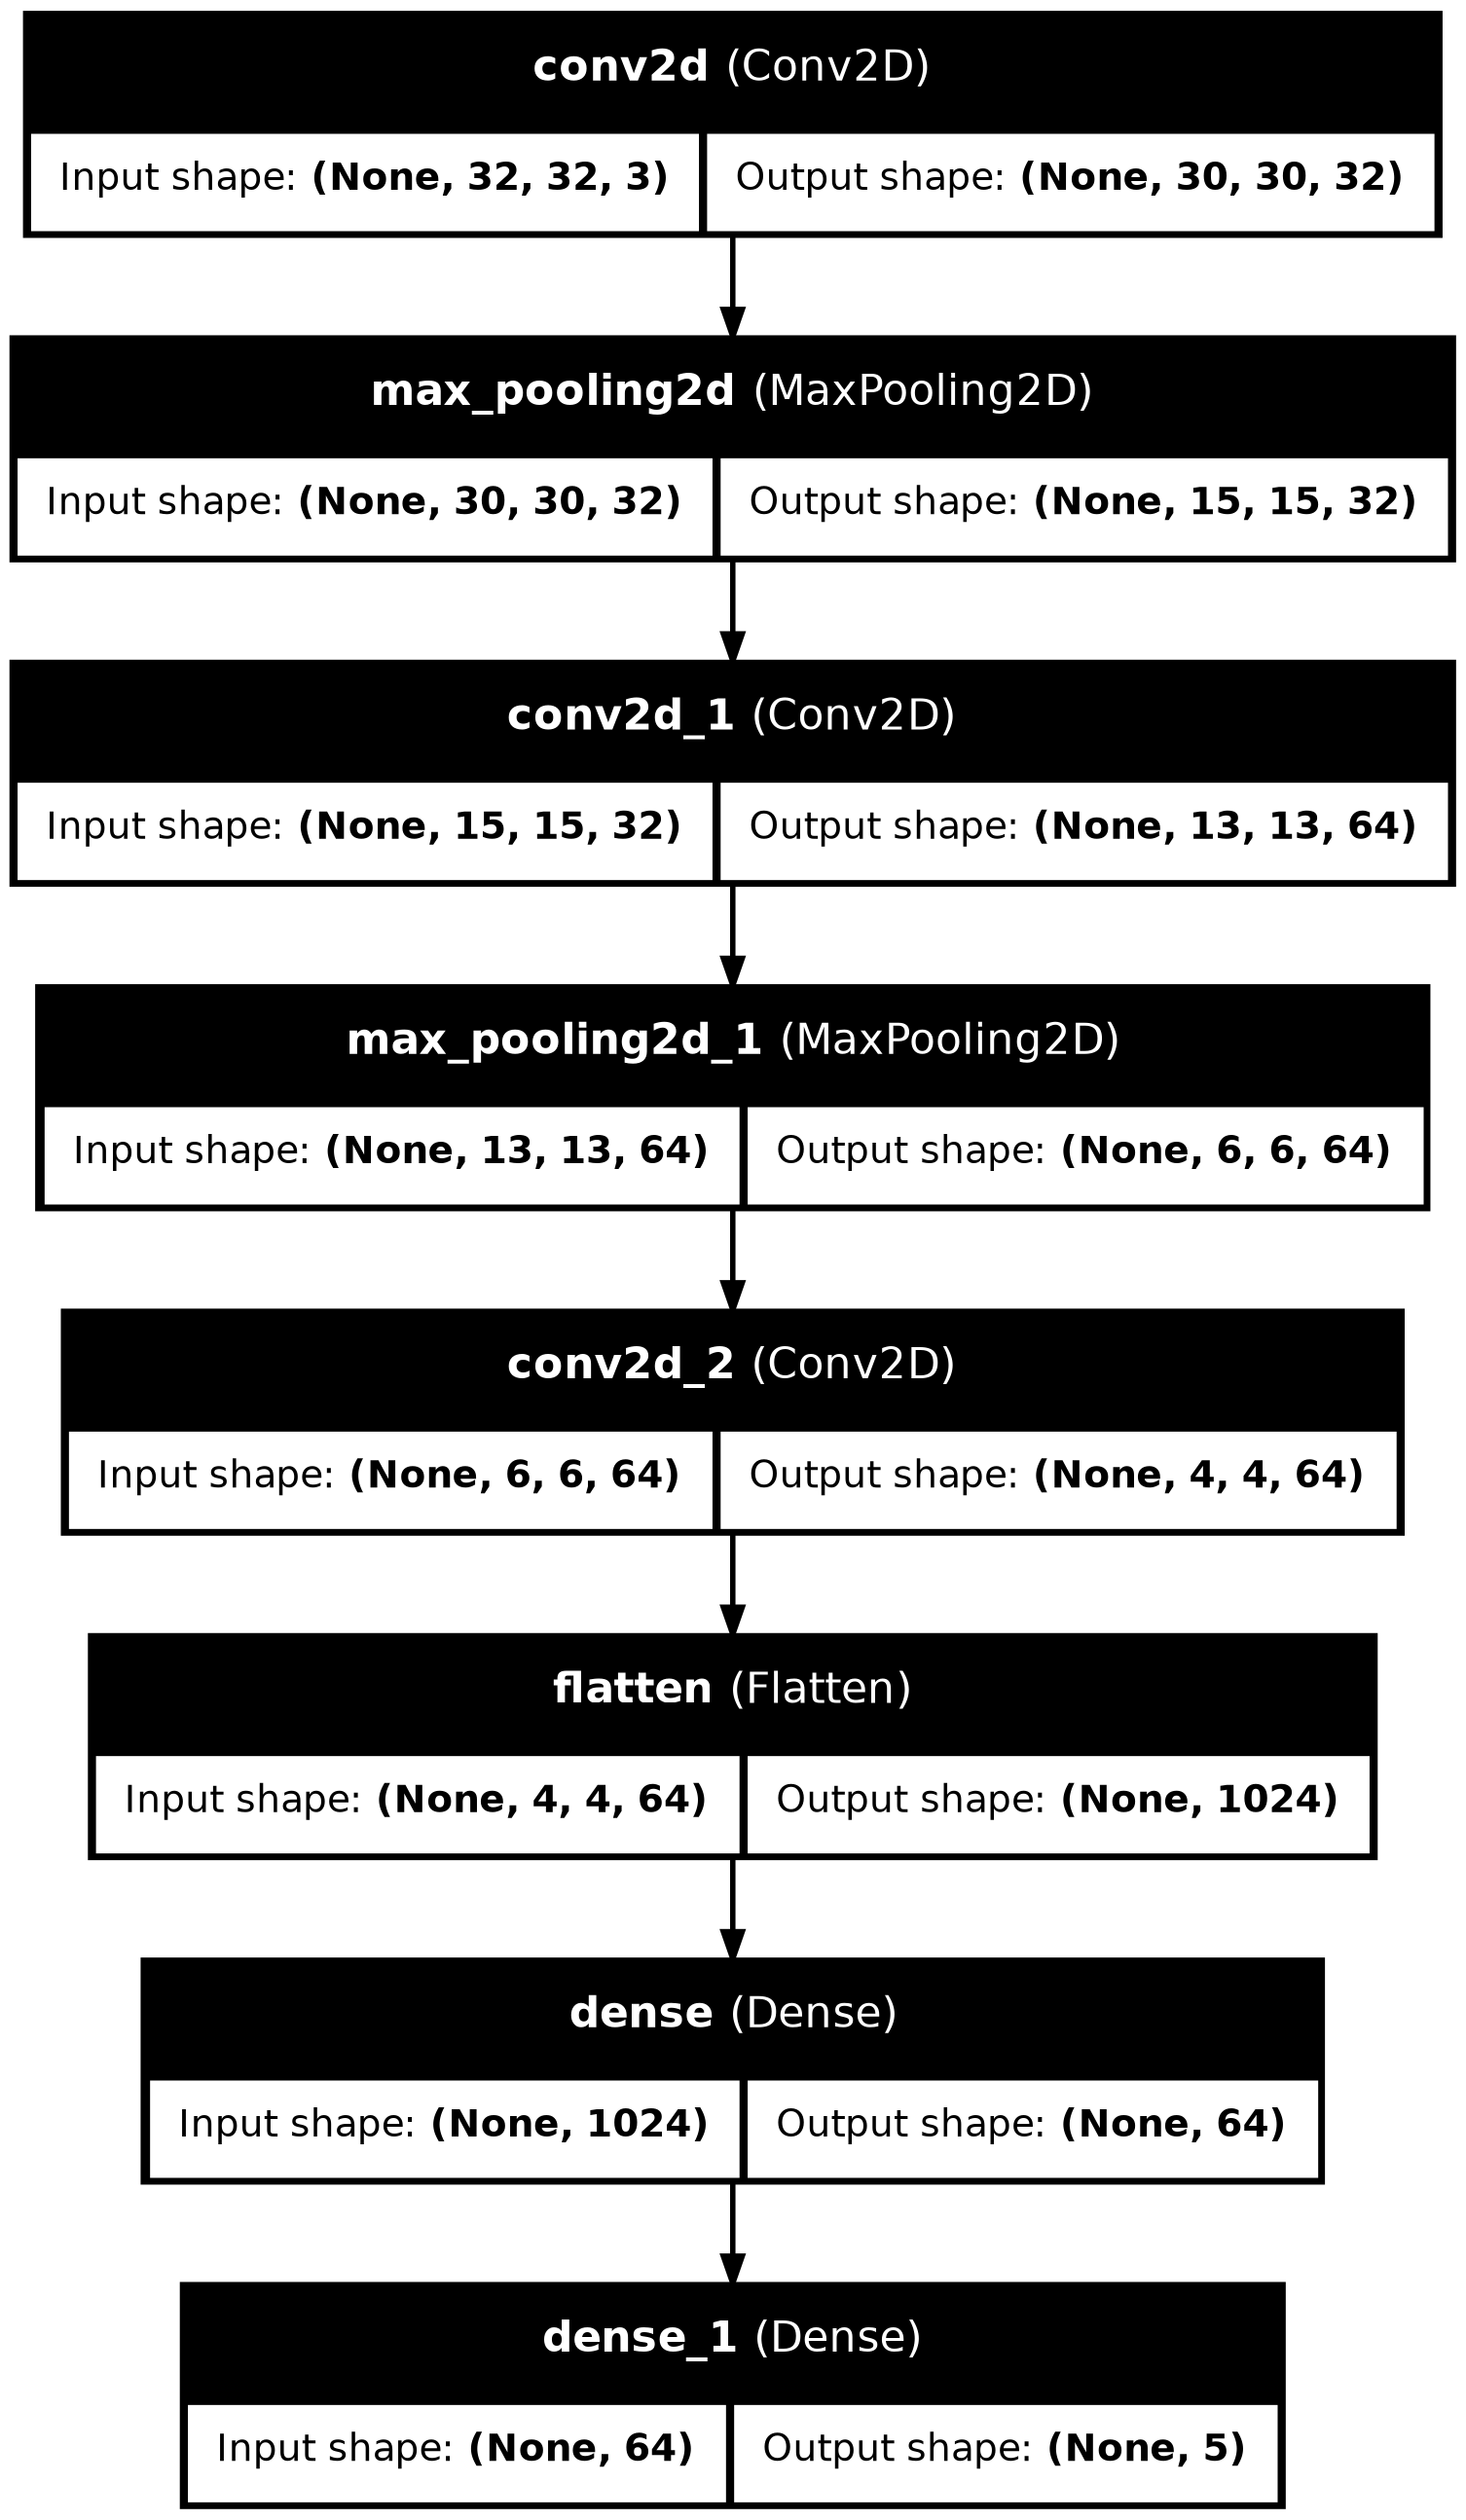

In [7]:
from tensorflow.keras.utils import plot_model
plot_model(model, to_file='model.png', show_shapes=True, show_layer_names=True)


<br><br>

---
###<font color='SeaGreen'>Step 3. Train and evaluate the model</font>

`model.fit` kelis kartus (epochas) praleidžia visą treniravimo imtį. `validation_data` po kiekvienos epochos matuoja testinę imtį — taip matome, ar tinklas mokosi, ar tik įsimena. Originalas: **20** CNN epochų. CPU aplinkoje sumažinta iki **8**; to pakanka palyginti CNN su perceptronu. Nuostolis `SparseCategoricalCrossentropy(from_logits=True)`, nes paskutinis sluoksnis be softmax (grąžina logit'us).

In [8]:
# Originaliame Colab: epochs=20. Sumažinta CPU laikui.
history = model.fit(train_images, train_labels, epochs=8, validation_data=(test_images, test_labels))


Epoch 1/8


 1/92 ━━━━━━━━━━━━━━━━━━━━ 1:17 849ms/step - accuracy: 0.1250 - loss: 1.6113

 7/92 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1875 - loss: 1.6098    

14/92 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2433 - loss: 1.5940

21/92 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2604 - loss: 1.5849

...

65/92 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6986 - loss: 0.7801

73/92 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7029 - loss: 0.7741

80/92 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7012 - loss: 0.7767

87/92 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7051 - loss: 0.7677

92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7050 - loss: 0.7675 - val_accuracy: 0.6717 - val_loss: 0.8501


####<font color='SeaGreen'>Evaluate the model</font>


23/23 - 0s - 4ms/step - accuracy: 0.6717 - loss: 0.8501


0.6716621518135071


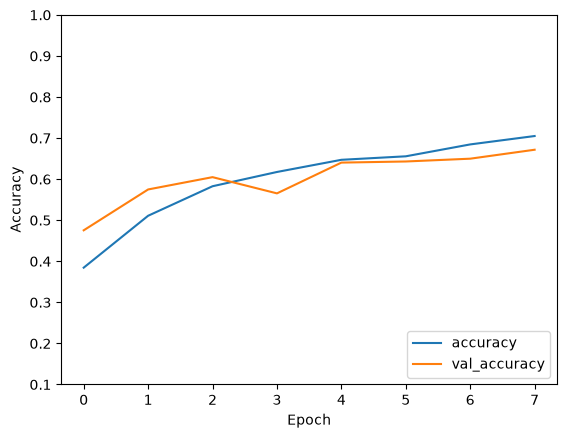

In [9]:
#@title CNN kreivės ir testinis tikslumas. Originaliame CIFAR-10 Colab minėta ~70 %; tf_flowers (5 klasės, 32×32) rezultatas bus kitoks.

plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.1, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)
print(test_acc)
cnn_test_acc = test_acc



<br><br>

---
# PART 2

2 dalis nebe moko tinklo — ji **paaiškina**, ką jau išmoko pirmasis konvoliucinis sluoksnis: piešiami filtrų svoriai ir požymių žemėlapiai (feature maps). Kodas paliktas kaip dėstytojo, nes vaizdai vis dar 32×32×3.

<font color='SeaGreen'>Visualizing Filters and Feature Maps</font> <img src="https://upload.wikimedia.org/wikipedia/commons/1/19/2D_Convolution_Animation.gif" width=200 height=200>


The simplest way to visualize learned filters in a neural network is to plot them as two-dimensional images. These filters, essentially weights, have a spatial relationship due to their two-dimensional structure. To view these filters, you can access the model's layers and identify convolutional layers with 'conv' in their names. Each convolutional layer has filter weights and bias values, which you can retrieve and examine. Typically, convolutional layers use 3x3 filters, and it's essential that the filter depth matches the input's channel depth. This process helps you understand the model's filter shapes and their compatibility with input channels.

**Lietuviškai.** Pirmasis `Conv2D` turi 32 filtrus formos 3×3×3 (aukštis × plotis × RGB kanalai). `get_weights()` grąžina filtrus ir poslinkius (bias). Piešdami atskirus kanalus matome, į kokį spalvinį šabloną reaguoja filtras. Toliau tas pats filtras praleidžiamas per vieną nuotrauką — gaunamas požymių žemėlapis. Galiausiai konvoliucija apskaičiuojama ranka (`numpy`) ir palyginama su Keras rezultatu (po ReLU).

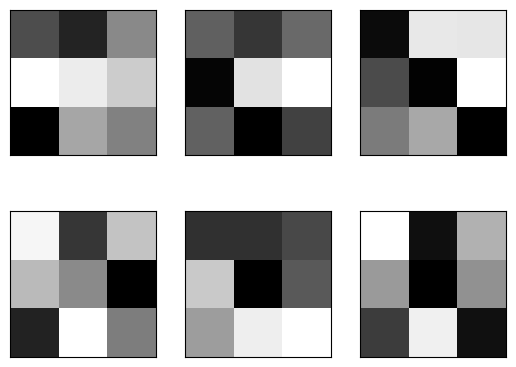

In [10]:
#@title These are the building blocks of our neural networks.

filters, biases = model.layers[0].get_weights()

ix = 1
for filter_i in range(2):
	filter_tmp = filters[:, :, :, filter_i]
	for channel_j in range(3):  # plot each channel separately
		ax = plt.subplot(2, 3, ix)
		ax.set_xticks([])
		ax.set_yticks([])
		plt.imshow(filter_tmp[:, :, channel_j], cmap='gray')
		ix += 1
plt.show()


In [11]:
filter_tmp[:, :, 0]


array([[ 0.09675564, -0.04604683,  0.05941904],
       [ 0.05271572,  0.01670257, -0.08625592],
       [-0.06062302,  0.10404041,  0.0070828 ]], dtype=float32)

In [12]:
#@title 📤 Let's delve into filter outputs.

model_layers_0 = tf.keras.Model(inputs=model.inputs, outputs=model.layers[0].output)  # redefine model to output right after the first hidden layer


In [13]:

img = train_images[1]  # load the image
img = np.expand_dims(img, axis=0)  # expand dimensions so that it represents a single 'sample'


feature_maps = model_layers_0.predict(img)  # get feature map for first hidden layer

#plt.figure(figsize=(5, 5));plt.imshow(train_images[1]);plt.axis('off');plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


In [14]:
transposed_img = np.transpose(train_images[1] , (2, 0, 1))
np.set_printoptions(threshold=np.inf)
for row in transposed_img[0]:
    formatted_row = ["{:0.2f}".format(element) for element in row]
    print(" ".join(formatted_row))


0.78 0.88 0.81 0.58 0.47 0.51 0.53 0.73 0.73 0.50 0.52 0.63 0.64 0.62 0.63 0.64 0.62 0.62 0.62 0.58 0.43 0.59 0.83 0.60 0.53 0.71 0.43 0.42 0.44 0.47 0.49 0.52
0.87 0.85 0.69 0.50 0.47 0.53 0.58 0.77 0.69 0.49 0.69 0.85 0.85 0.82 0.83 0.85 0.83 0.82 0.84 0.82 0.56 0.53 0.85 0.69 0.46 0.73 0.56 0.40 0.41 0.43 0.47 0.49
0.86 0.76 0.55 0.46 0.51 0.55 0.65 0.80 0.64 0.51 0.81 0.94 0.93 0.91 0.92 0.91 0.91 0.90 0.93 0.91 0.75 0.52 0.80 0.73 0.44 0.64 0.73 0.45 0.39 0.40 0.44 0.47
0.75 0.64 0.49 0.49 0.53 0.58 0.73 0.80 0.60 0.54 0.84 0.93 0.90 0.85 0.89 0.86 0.89 0.85 0.88 0.85 0.80 0.59 0.73 0.80 0.48 0.53 0.78 0.60 0.40 0.44 0.44 0.45
0.67 0.54 0.46 0.51 0.54 0.64 0.79 0.77 0.56 0.59 0.87 0.91 0.88 0.77 0.83 0.82 0.86 0.76 0.80 0.84 0.85 0.74 0.68 0.85 0.58 0.44 0.67 0.75 0.50 0.42 0.49 0.44
0.59 0.47 0.48 0.52 0.59 0.70 0.82 0.71 0.55 0.66 0.91 0.92 0.87 0.78 0.85 0.88 0.89 0.73 0.75 0.87 0.91 0.85 0.69 0.83 0.67 0.42 0.55 0.80 0.68 0.43 0.46 0.55
0.49 0.46 0.50 0.56 0.63 0.76 0.82 0.64 

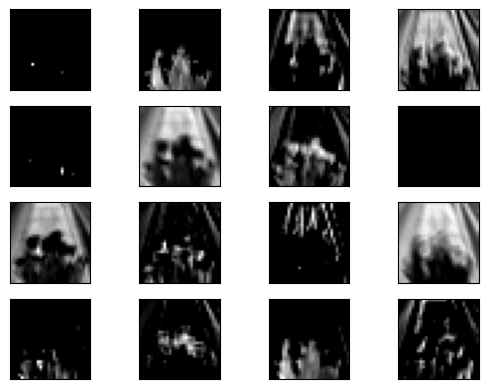

In [15]:
#@title 📍 feature maps created by the filters from the first layer of our trained CNN. Each filter extracts a unique facet.

ix = 1
for _ in range(4):
  for _ in range(4):
    if ix > 32:
      break
    # specify subplot and turn of axis
    ax = plt.subplot(4, 4, ix)
    ax.set_xticks([])
    ax.set_yticks([])
    # plot filter channel in grayscale
    plt.imshow(feature_maps[0, :, :, ix-1], cmap='gray')
    ix += 1


In [16]:
train_images[1].shape


(32, 32, 3)

In [17]:
filter = filters[:,:,:,2]
filter.shape


(3, 3, 3)

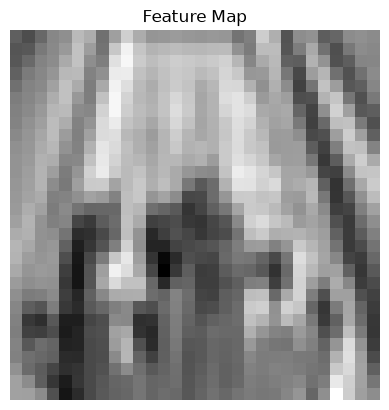

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming train_images[1] is your input image (32x32x3) and filter has shape (3, 3, 3)
input_image = train_images[1]


# Perform convolution
feature_map = np.zeros((input_image.shape[0] - filter.shape[0] + 1, input_image.shape[1] - filter.shape[1] + 1))

for i in range(feature_map.shape[0]):
    for j in range(feature_map.shape[1]):
        feature_map[i, j] = np.sum(input_image[i:i+filter.shape[0], j:j+filter.shape[1], :] * filter)

# Display the feature map
plt.imshow(feature_map, cmap='gray')
plt.title("Feature Map")
plt.axis('off')
plt.show()


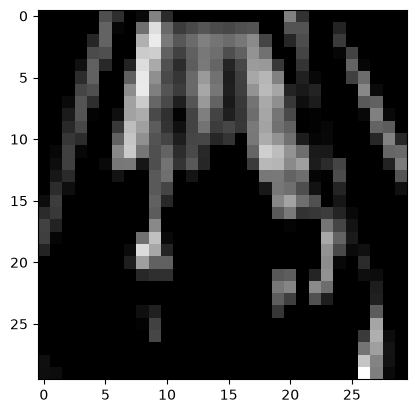

In [19]:
plt.imshow(feature_maps[0, :, :, 2], cmap='gray')


In [20]:
bias = biases[2]
bias


np.float32(-0.035094418)

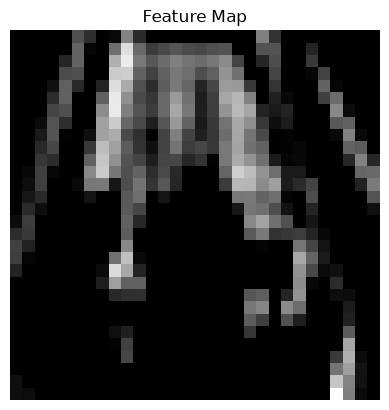

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming train_images[1] is your input image (32x32x3) and filter has shape (3, 3, 3)
input_image = train_images[1]


# Perform convolution
feature_map = np.zeros((input_image.shape[0] - filter.shape[0] + 1, input_image.shape[1] - filter.shape[1] + 1))

for i in range(feature_map.shape[0]):
    for j in range(feature_map.shape[1]):
        feature_map[i, j] = np.sum(input_image[i:i+filter.shape[0], j:j+filter.shape[1], :] * filter) + bias


# Apply ReLU activation
feature_map[feature_map < 0] = 0

# Display the feature map
plt.imshow(feature_map, cmap='gray')
plt.title("Feature Map")
plt.axis('off')
plt.show()


In [22]:
feature_map_tmp = feature_maps[0, :, :, 2]
print(feature_map_tmp.shape)
print(feature_map_tmp[:6,:6])


(30, 30)
[[0.         0.         0.         0.         0.         0.06795853]
 [0.         0.         0.         0.         0.         0.08439027]
 [0.         0.         0.         0.         0.03297614 0.0844336 ]
 [0.         0.         0.         0.         0.0642762  0.06783631]
 [0.         0.         0.         0.01414068 0.08234824 0.03451667]
 [0.         0.         0.         0.0384486  0.0827297  0.        ]]


In [23]:
print(feature_map.shape)
print(feature_map[:6,:6])


(30, 30)
[[0.         0.         0.         0.         0.         0.06795854]
 [0.         0.         0.         0.         0.         0.08439027]
 [0.         0.         0.         0.         0.03297614 0.08443358]
 [0.         0.         0.         0.         0.06427618 0.06783631]
 [0.         0.         0.         0.01414069 0.08234824 0.03451665]
 [0.         0.         0.         0.03844859 0.08272969 0.        ]]





<br><br><br><br><br><br>

---
#<font color='SeaGreen'>PART 3. Image classification with Multilayer perceptron</font> <img src="https://upload.wikimedia.org/wikipedia/commons/thumb/4/46/Colored_neural_network.svg/250px-Colored_neural_network.svg.png" width=150 height=150>

**Kodėl MLP silpnesnis.** Daugiasluoksnis perceptronas iškart `Flatten` paverčia 32×32×3 vaizdą 3072 skaičių vektoriumi ir neieško vietinių šablonų. CNN dalijasi filtrų svoriais erdvėje, todėl geriau tinka vaizdams. Originaliame CIFAR-10 Colab MLP gavo ~40 %, CNN ~70 %. Čia tas pats palyginimas su tf_flowers; išėjimas vėl 5 klasės.



<br><br>

---
###<font color='SeaGreen'>Step 2. Model. Multilayer perceptron</font>


In [24]:
model = models.Sequential()
model.add(layers.Flatten(input_shape=(32, 32,3)))
model.add(layers.Dense(32, activation='relu'))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(5))

model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),  metrics=['accuracy'])


/home/ubuntu/.local/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [25]:
#@title Let's display the architecture of  model:

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │        98,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,933 (409.89 KB)

 Trainable params: 104,933 (409.89 KB)

 Non-trainable params: 0 (0.00 B)



<br><br>

---
###<font color='SeaGreen'>Step 3. Train and evaluate the model</font>

Originalas: **15** MLP epochų. CPU: **5** epochos (pakanka pamatyti, kad perceptronas atsilieka nuo CNN).

In [26]:
# Originaliame Colab: epochs=15. Sumažinta CPU laikui.
history = model.fit(train_images, train_labels, epochs=5, validation_data=(test_images, test_labels))


Epoch 1/5


 1/92 ━━━━━━━━━━━━━━━━━━━━ 51s 562ms/step - accuracy: 0.1250 - loss: 1.6716

31/92 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2530 - loss: 1.6200   

62/92 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3070 - loss: 1.5466

92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3362 - loss: 1.4947 - val_accuracy: 0.4033 - val_loss: 1.3341


...

Epoch 5/5


 1/92 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5625 - loss: 1.1291

32/92 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4863 - loss: 1.1949 

65/92 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4851 - loss: 1.1943

92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4782 - loss: 1.2011 - val_accuracy: 0.4537 - val_loss: 1.2639


####<font color='SeaGreen'>Evaluate the model</font>


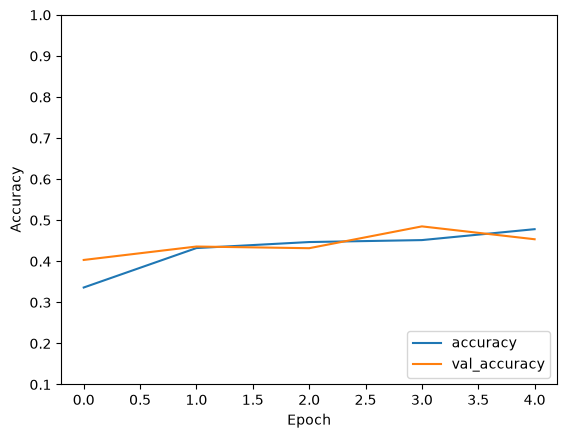

In [27]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.1, 1])
plt.legend(loc='lower right')


In [28]:
#@title Paprastas perceptronas silpnesnis už CNN — originaliame CIFAR-10 Colab minėta ~40 %.

test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)
print(test_acc)
mlp_test_acc = test_acc
print("CNN test accuracy:", cnn_test_acc)
print("MLP test accuracy:", mlp_test_acc)


23/23 - 0s - 2ms/step - accuracy: 0.4537 - loss: 1.2639


0.4536784887313843
CNN test accuracy: 0.6716621518135071
MLP test accuracy: 0.4536784887313843
